
# Credit Pre-Screening Engine — Loan Intake Optimisation

### Calibo AI Academy | Phase 2 — Mini Use Case 02

**Industry:** BFSI — Retail Lending (Personal Loans)

**Batch:** Path 3 — Online Batch

**Modules Covered:** Supervised Learning — Parts 1 & 2, Unsupervised Learning, Model Selection and Validation

---

## 1. Project Overview

This project focuses on developing a Credit Pre-Screening Engine to help a bank improve its personal loan application review process using machine learning.

The bank receives approximately 3,000 loan applications per month, and each application takes a credit analyst around 25 minutes to review manually. The objective is to use six months of historical application data and final credit-team decisions to identify clear-cut declines and potential approvals, allowing analysts to focus on applications that require human judgement.

## 2. Business Problem Statement

The bank wants to understand whether historical loan application data can be used to build a reliable pre-screening model that reduces manual review workload while controlling credit risk.

The solution must identify applications suitable for preliminary screening, minimise wrongly declined creditworthy applicants, avoid fast-tracking risky applications, and support transparent and fair decision-making.

## 3. Project Objectives

- Understand the business problem and historical loan application data.
- Inspect, clean and preprocess the dataset with justified decisions.
- Analyse historical approval patterns and important credit-risk factors.
- Engineer FOIR, loan-to-income and new-to-credit features.
- Build and evaluate a Logistic Regression baseline classifier.
- Select an auto-decline threshold that satisfies the bank's 5% risk limit.
- Examine fairness across gender and potential proxy variables.
- Build a reusable machine learning pipeline.
- Compare four classification models using five-fold stratified cross-validation.
- Design a two-lane pre-screening system with auto-decline, analyst-review and fast-track lanes.
- Compare models based on performance, explainability, risk and business impact.
- Provide actionable recommendations for the Credit Policy Analyst.
- Apply K-Means clustering as an optional extension to identify applicant segments.

## 4. Tools and Technologies

- Python
- Google Colab / Jupyter Notebook
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn

## 5. Dataset Overview

**Dataset file:** `MUC02_Credit_PreScreening_Dataset.csv`

The dataset contains 12,000 personal loan applications received between April and September 2026. Each row represents one application, and the `decision` column records the final decision made by the bank's credit team.

The dataset includes applicant demographics, employment details, income, existing financial obligations, credit history, requested loan information and the final credit decision.

## 6. Expected Deliverables

1. A Jupyter Notebook covering Steps 5.1–5.11, with Step 5.12 included if attempted.
2. A completed CBIM Problem Canvas, placed separately at the top of the notebook or submitted as a separate document.
3. A one-page written insight summary of no more than 400 words.
4. A fully tested notebook that runs from beginning to end without errors.

## 7. Project Approach

The project will follow a structured workflow covering business understanding, data preparation, feature engineering, supervised learning, model validation, threshold selection, fairness assessment, unsupervised learning as an optional extension, and business recommendations.

**Important principle:** The goal is not simply to achieve the highest accuracy. The goal is to develop a useful and explainable pre-screening approach that improves loan intake efficiency while respecting the bank's risk limits.

Model predictions will support preliminary screening and will not be used as the sole basis for final loan approval or rejection.



# CBIM Problem Canvas

## 1. Situation

A mid-size private bank in India provides unsecured personal loans to salaried employees, self-employed professionals, business owners and gig workers. The bank receives approximately 3,000 applications every month, and each application takes around 25 minutes for a credit analyst to review manually.

## 2. Complication

Manual reviews consume significant analyst time, including time spent on applications that may be declined due to clear credit-risk indicators. This reduces the time available for applications that need detailed investigation and human judgement. The bank wants to improve efficiency without wrongly declining creditworthy applicants or fast-tracking risky applications.

## 3. Question

Using six months of historical loan applications and their final credit-team decisions, how much of the manual review queue can a pre-screening model safely reduce while meeting the bank's risk limits?

## 4. SSOT (Single Source of Truth)

The provided dataset, `MUC02_Credit_PreScreening_Dataset.csv`, is the single source of truth for this analysis. Each row represents one loan application, and the `decision` column contains the historical final decision made by the credit team: Approved or Declined.

## 5. Success Definition

The pre-screening solution should reduce manual reviews while satisfying both business risk limits:

- No more than 5% of applications in the auto-decline lane should have been historically approved.
- No more than 5% of applications in the fast-track lane should have been historically declined.

The solution should also demonstrate useful predictive performance, explainability, fairness awareness and measurable monthly analyst-time savings.

## 6. Primary Stakeholder

The primary stakeholder is the Credit Policy Analyst, who must present a clear and defensible recommendation to the Head of Retail Lending. Credit analysts, loan applicants and the bank are also affected by the screening decisions.



# Step 5.1 — Load, Inspect, and Clean the Dataset

## Objective

The first step is to load the credit pre-screening dataset and understand its structure before making any changes.

## Why are we doing this?

Before building a machine learning model, we need to understand how many applications are present, what information each column contains, whether any values are missing, and whether duplicate records exist.

We will also calculate the historical approval rate to understand the bank's existing lending decisions.

## Business Relevance

Checking the data quality helps us avoid incorrect conclusions and unreliable predictions. We will investigate missing monthly income, missing credit scores, and unusually high income values before deciding how to handle them.

**Important:** Applicants with missing credit scores should not automatically be removed because they may be new-to-credit applicants with no previous credit history.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\madhu\AppData\Roaming\Python\Python312\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [2]:

df = pd.read_csv("MUC02_Credit_PreScreening_Dataset.csv")


In [3]:

df.shape


(12000, 19)


### Understanding the Dataset Structure

The first five rows help us understand how individual loan applications are recorded in the dataset. Each row represents one application, and each column contains information such as applicant details, income, credit history, loan details, or the final credit decision.

In the next step, we will examine the column names and data types to identify numerical and categorical variables. This is important because different types of data may require different preprocessing methods before machine learning.


In [4]:

df.head()


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.1,95000.0,23500.0,784.0,109,2,0,Home Renovation,240000.0,48,6600.0,Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.6,43000.0,8500.0,790.0,162,2,0,Wedding,145000.0,36,5000.0,Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.4,35000.0,3500.0,718.0,151,1,1,Medical,345000.0,36,11800.0,Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.8,44500.0,0.0,NaN,0,0,0,Travel,135000.0,36,4600.0,Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.1,83500.0,6000.0,700.0,127,1,3,Medical,700000.0,24,33600.0,Declined



### Checking Column Names and Data Types

In this step, we will examine all the columns and their data types using Pandas.

Numerical columns contain values such as age, income, credit score and loan amount. Categorical columns contain labels such as gender, employment type, city and loan decision.

Understanding these data types helps us identify which preprocessing methods may be required before building the machine learning model.


In [5]:

df.info()


<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 19 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   application_id         12000 non-null  str    
 1   application_date       12000 non-null  str    
 2   age                    12000 non-null  int64  
 3   gender                 12000 non-null  str    
 4   city                   12000 non-null  str    
 5   city_tier              12000 non-null  int64  
 6   employment_type        12000 non-null  str    
 7   years_in_current_job   12000 non-null  float64
 8   monthly_income         11559 non-null  float64
 9   existing_emi           12000 non-null  float64
 10  credit_score           10961 non-null  float64
 11  credit_history_months  12000 non-null  int64  
 12  num_active_loans       12000 non-null  int64  
 13  delinquencies_24m      12000 non-null  int64  
 14  loan_purpose           12000 non-null  str    
 15  loan_amount  


### Checking Missing Values

Missing values occur when information is not available for some loan applications. Before building a machine learning model, we need to identify which columns contain missing data and how many values are missing.

From the dataset information, monthly_income and credit_score contain missing values. Missing monthly income may affect affordability calculations, while a missing credit score may indicate an applicant with no established credit history.

We will examine the exact missing-value counts before deciding how to handle them. We should not automatically remove applicants with missing credit scores because they may be new-to-credit applicants.


In [6]:
df.isnull().sum()

application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income            441
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
dtype: int64


### Checking Duplicate Records

Duplicate records occur when the same record appears more than once in a dataset. They can affect our analysis and may cause the same loan application to be counted multiple times.

Before removing anything, we will count the duplicate rows. If duplicates exist, we will investigate and decide whether they should be removed.


In [7]:
df.duplicated().sum()

0


### Understanding the Loan Decision Distribution

The decision column contains the historical loan outcomes: Approved or Declined. We need to understand how many applications fall into each category and calculate the overall approval rate.

This helps us understand the bank's existing lending decisions and the balance between approved and declined applications. We will use this information as a baseline for evaluating our pre-screening model.


In [8]:
decision_counts = df["decision"].value_counts()

approval_rate = (df["decision"].eq("Approved").mean()) * 100
decline_rate = (df["decision"].eq("Declined").mean()) * 100

print("Loan Decision Counts:")
print(decision_counts)

print(f"\nOverall Approval Rate: {approval_rate:.2f}%")
print(f"Overall Decline Rate: {decline_rate:.2f}%")

Loan Decision Counts:
decision
Approved    6353
Declined    5647
Name: count, dtype: int64

Overall Approval Rate: 52.94%
Overall Decline Rate: 47.06%


Interpretation of the results
- Total applications: 12,000
- Approved: 6,353 applications (52.94%)
- Declined: 5,647 applications (47.06%)
Business understanding: Nearly 47% of applications were declined historically. The goal of our project is to identify clear declines and suitable approvals so the bank can reduce manual review time while keeping lending decisions safe.


### Investigating Missing Monthly Income by Employment Type

Monthly income is important for assessing whether an applicant can afford a loan. Missing income values may affect calculations such as FOIR and loan-to-income ratio.

We will check how missing monthly income is distributed across employment types. This will help us understand whether missing income is concentrated in a particular group and choose a suitable imputation method based on the evidence.


In [9]:
missing_income_by_employment = df.groupby("employment_type")["monthly_income"].apply(
    lambda x: x.isnull().sum()
)

total_by_employment = df["employment_type"].value_counts()

missing_income_summary = pd.DataFrame({
    "Total Applications": total_by_employment,
    "Missing Monthly Income": missing_income_by_employment
})

missing_income_summary["Missing Income Percentage"] = (
    missing_income_summary["Missing Monthly Income"]
    / missing_income_summary["Total Applications"] * 100
).round(2)

missing_income_summary

,Total Applications,Missing Monthly Income,Missing Income Percentage
employment_type,,,
Business Owner,1749,227,12.98
Gig / Contract,1766,11,0.62
Salaried,7057,49,0.69
Self-Employed Professional,1428,154,10.78


Interpretation of the results
- Business Owner: 12.98% missing income — the highest.
- Self-Employed Professional: 10.78% missing income.
- Salaried: 0.69% missing income.
- Gig / Contract: 0.62% missing income.
Business understanding: Missing income is much more common among business owners and self-employed professionals. We should investigate this pattern before selecting an imputation method. Using the overall median without considering employment type could hide differences between these groups.


### Investigating Missing Credit Scores and Credit History

Credit scores help the bank understand an applicant's creditworthiness. However, a missing credit score does not always mean the data is incorrect. Some applicants may be new-to-credit and may not have an established credit history.

We will compare applications with missing credit scores against credit_history_months. This will help us understand whether these applicants have no credit history or whether their credit score is missing despite having an existing credit history.

We will not automatically remove these applications because new-to-credit applicants are also important for lending decisions.


In [10]:
missing_score_summary = df.groupby(
    df["credit_score"].isnull()
)["credit_history_months"].agg(
    Total_Applications="count",
    Minimum_History_Months="min",
    Maximum_History_Months="max",
    Zero_History_Count=lambda x: (x == 0).sum()
)

missing_score_summary.index = [
    "Credit Score Available",
    "Credit Score Missing"
]

missing_score_summary

,Total_Applications,Minimum_History_Months,Maximum_History_Months,Zero_History_Count
Credit Score Available,10961,6,395,0
Credit Score Missing,1039,0,0,1039


Interpretation of the results
- Credit score available: 10,961 applications.
- Credit score missing: 1,039 applications.
- All 1,039 applications with missing credit scores have credit_history_months = 0.
- Applicants with an available credit score have at least 6 months of credit history.
Business understanding: The missing credit scores are associated with applicants who have no established credit history. These are new-to-credit (NTC) applicants, not random missing values in this dataset. We should retain these applications and create an is_ntc feature to identify them, as required by the project.


### Investigating Unusually High Monthly Income

Monthly income is used to evaluate loan affordability. If some applicants have entered annual income instead of monthly income, their values may be unusually high and could affect the model.

We will inspect the maximum monthly income and the highest income records before deciding whether any values need correction. We should not change or remove values without evidence that they are incorrect.


In [11]:
df["monthly_income"].max()

1656000.0

Interpretation
- The maximum value is ₹16,56,000 per month.
- This may be a genuine high income or a possible data-entry issue, such as annual income entered as monthly income.
- We need to inspect the highest income records before deciding whether any correction is justified.


### Inspecting the Highest Monthly Income Records

The maximum monthly income is ₹16,56,000. Before making any changes, we will inspect the highest income records along with employment type and other relevant details.

This will help us check whether these values appear plausible and whether there is evidence of annual income being entered as monthly income. We will document any cleaning decision based on the observed data rather than changing values based only on their size.


In [12]:
df.nlargest(10, "monthly_income")[
    ["application_id", "employment_type", "monthly_income",
     "existing_emi", "loan_amount", "decision"]
]

,application_id,employment_type,monthly_income,existing_emi,loan_amount,decision
1467,APP101468,Salaried,1656000.0,16500.0,925000.0,Declined
300,APP100301,Salaried,1254000.0,0.0,240000.0,Approved
2493,APP102494,Salaried,1212000.0,23500.0,600000.0,Approved
589,APP100590,Salaried,1068000.0,13500.0,600000.0,Declined
9849,APP109850,Salaried,990000.0,21000.0,260000.0,Declined
1848,APP101849,Salaried,984000.0,0.0,500000.0,Approved
2488,APP102489,Salaried,972000.0,0.0,310000.0,Approved
4010,APP104011,Salaried,900000.0,4000.0,580000.0,Approved
4898,APP104899,Salaried,870000.0,4500.0,645000.0,Declined
9261,APP109262,Salaried,702000.0,0.0,495000.0,Approved


Interpretation of the results
- The highest monthly income is ₹16,56,000.
- All 10 records belong to Salaried applicants.
- Some applications were approved and others declined, so high income alone does not determine the bank's decision.
- The values could represent genuine high incomes or possible annual-income entry errors. We need more evidence before changing them.
Cleaning decision for now: We will not automatically remove or modify these values. We will document the unusually high values for further investigation.


### Data Quality Findings and Initial Cleaning Decisions

The dataset contains 12,000 applications and has no exact duplicate rows. Missing values occur only in monthly_income (441 records) and credit_score (1,039 records). Missing monthly income is concentrated among Business Owners and Self-Employed Professionals, so we will investigate a suitable imputation approach. All applications with missing credit scores have zero credit history months, so we will retain them and identify them as new-to-credit applicants. The maximum monthly income is ₹16,56,000; we have not changed these high values because the available evidence does not prove that they are incorrect.

These findings will guide the next data-cleaning steps before feature engineering and model building.



### Planning the Missing-Value Treatment

Before cleaning the dataset, we need to decide how to handle the missing monthly_income and credit_score values.

For monthly_income, we will compare suitable imputation options and consider the differences between employment types. For credit_score, we will preserve the new-to-credit information using the is_ntc feature and impute missing scores only when preparing the model features.

We will also check the dataset instructions before making any changes to unusually high income values. Our goal is to prepare reliable data without removing useful loan applications or making unsupported corrections.


In [13]:
df.groupby("employment_type")["monthly_income"].agg(
    ["count", "median", "mean", "min", "max"]
).round(2)

,count,median,mean,min,max
employment_type,,,,,
Business Owner,1522,69500.0,79441.52,12000.0,330000.0
Gig / Contract,1755,28000.0,32152.14,12000.0,170000.0
Salaried,7008,50000.0,58827.34,12000.0,1656000.0
Self-Employed Professional,1274,75000.0,84443.09,12000.0,349000.0


Interpretation of the results
- Business Owner: Median income ₹69,500.
- Gig / Contract: Median income ₹28,000.
- Salaried: Median income ₹50,000.
- Self-Employed Professional: Median income ₹75,000.
The median incomes differ across employment types. Also, the Salaried group has a much higher maximum income than its median, suggesting that its income distribution may contain extreme values.

Cleaning decision: We can use the median income within each employment type to fill missing monthly income values. This preserves the differences between employment groups and is less affected by extreme values than the mean.


### Handling Missing Monthly Income

Our investigation shows that typical monthly income differs across employment types. We will fill missing monthly_income values using the median income of the applicant's employment type.

The median is suitable because it is less affected by unusually high values than the mean. This approach allows us to retain applications with missing income instead of deleting them.

We will preserve the original dataset and create a cleaned working copy so that the changes are clear and reproducible.


In [14]:
df_clean = df.copy()

df_clean["monthly_income"] = df_clean.groupby("employment_type")[
    "monthly_income"
].transform(lambda x: x.fillna(x.median()))

print("Missing monthly_income before cleaning:", df["monthly_income"].isnull().sum())
print("Missing monthly_income after cleaning:", df_clean["monthly_income"].isnull().sum())

Missing monthly_income before cleaning: 441
Missing monthly_income after cleaning: 0


Interpretation
- Before cleaning: 441 missing values.
- After cleaning: 0 missing values.
- We used the median income for each employment type.
- We retained all 12,000 applications.
Business understanding: We can now use monthly income in affordability calculations without losing applications simply because their income was missing.


### Handling Missing Credit Scores

Our investigation showed that all 1,039 applications with missing credit scores have zero credit history months. These applicants are new-to-credit applicants.

We should not treat them as ordinary records with missing information or remove them from the dataset. We will create an is_ntc feature to identify applicants with no credit score. Later, when preparing the model, we will impute missing credit scores using the median of the available scores while retaining the is_ntc indicator.

This allows the model to use credit score information where available while preserving the distinction between applicants with and without established credit history.


In [15]:
df_clean["is_ntc"] = df_clean["credit_score"].isnull().astype(int)

print("New-to-credit applicants:", df_clean["is_ntc"].sum())
print("Applicants with an available credit score:", (df_clean["is_ntc"] == 0).sum())
print("Missing credit scores remaining:", df_clean["credit_score"].isnull().sum())

New-to-credit applicants: 1039
Applicants with an available credit score: 10961
Missing credit scores remaining: 1039


Interpretation
- New-to-credit applicants: 1,039 (is_ntc = 1)
- Applicants with an available credit score: 10,961 (is_ntc = 0)
- Missing credit scores remaining: 1,039
We are intentionally keeping those missing credit scores for now. The is_ntc feature preserves the important information that these applicants have no established credit history.


### Verifying the Initial Cleaning Results

We have filled missing monthly income values using the median for each employment type and created the is_ntc feature for applicants with missing credit scores.

Before continuing, we will verify the remaining missing values and confirm that the dataset still contains all 12,000 applications. Credit score values will remain missing in the working dataset for now because we plan to impute them as part of the model preprocessing pipeline.


In [16]:
print("Dataset shape:", df_clean.shape)

print("\nMissing values after initial cleaning:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

Dataset shape: (12000, 20)

Missing values after initial cleaning:
application_id              0
application_date            0
age                         0
gender                      0
city                        0
city_tier                   0
employment_type             0
years_in_current_job        0
monthly_income              0
existing_emi                0
credit_score             1039
credit_history_months       0
num_active_loans            0
delinquencies_24m           0
loan_purpose                0
loan_amount                 0
tenure_months               0
proposed_emi                0
decision                    0
is_ntc                      0
dtype: int64

Total missing values: 1039



### Checking the Application Date Format

The application_date column currently has a text data type. Converting it to a proper date format would allow us to sort and analyze applications by date.

However, application_date is not one of the specified model features. We will inspect its format and keep it available for reporting and identifying recent applications, while excluding it from the model features as required by the project instructions.


In [17]:
df_clean["application_date"] = pd.to_datetime(
    df_clean["application_date"],
    errors="coerce"
)

print("Application date data type:", df_clean["application_date"].dtype)
print("Invalid or missing dates:", df_clean["application_date"].isnull().sum())

print("\nEarliest application date:", df_clean["application_date"].min())
print("Latest application date:", df_clean["application_date"].max())

Application date data type: datetime64[us]
Invalid or missing dates: 0

Earliest application date: 2026-04-01 00:00:00
Latest application date: 2026-09-30 00:00:00


Interpretation of the results
- Data type: datetime64[us] — the application date is now stored as a date/time value.
- Invalid or missing dates: 0.
- Earliest date: 1 April 2026.
- Latest date: 30 September 2026.
Business understanding: The dataset covers six months of loan applications, from April through September 2026, matching the project brief. We can use the date column for reporting and identifying recent applications, but we will exclude it from model features to follow the instructions.


### Step 5.1 — Data Inspection and Initial Cleaning Summary

The dataset contains 12,000 loan applications and 19 original columns. We found no duplicate rows, and the historical approval and decline rates are 52.94% and 47.06%, respectively. We filled 441 missing monthly income values using the median for each employment type because income patterns differ across employment groups. We retained all 1,039 applicants with missing credit scores because they have zero credit history months, and created the is_ntc indicator to identify them. The highest recorded monthly income is ₹16,56,000; we have not changed it because we do not yet have enough evidence to classify it as an error. Finally, we converted application_date into a proper date format, with no invalid dates found.

These initial checks prepare the dataset for the next analysis steps. We will continue to investigate credit-score groups, approval patterns, and affordability before building the models.



## Step 5.2 — Analyze Credit Score Groups and Approval Rates

Credit score is an important factor in loan decisions because it helps the bank understand an applicant's credit history. We will group applicants into the credit-score ranges specified in the project instructions and calculate the historical approval rate for each group.

Applicants without a credit score will be placed in a separate No score group. This is important because they may be new-to-credit applicants rather than applicants with a low credit score.

We will also compare approval rates across employment types. These comparisons will help us understand historical lending patterns and identify groups that may require closer attention during pre-screening.


In [19]:
def group_credit_score(score):
    if pd.isna(score):
        return "No score"
    elif score < 600:
        return "Below 600"
    elif score < 650:
        return "600–649"
    elif score < 700:
        return "650–699"
    elif score < 750:
        return "700–749"
    elif score < 800:
        return "750–799"
    else:
        return "800+"

df_clean["credit_score_group"] = df_clean["credit_score"].apply(
    group_credit_score
)

df_clean["credit_score_group"].value_counts()

credit_score_group
700–749      3377
650–699      2529
750–799      2526
800+         1350
No score     1039
600–649       933
Below 600     246
Name: count, dtype: int64

Interpretation of the results
- 700–749: 3,377 applications — the largest group.
- 650–699: 2,529 applications.
- 750–799: 2,526 applications.
- 800+: 1,350 applications.
- No score: 1,039 applications.
- 600–649: 933 applications.
- Below 600: 246 applications — the smallest group.
These are the application counts, not approval rates. Next, we'll calculate the percentage approved in each group to understand how historical decisions vary by credit score.


### Calculating Approval Rates by Credit Score Group

Now that we have created the required credit-score groups, we will calculate the number of approved applications and the approval rate within each group.

The approval rate is the percentage of applications in a group that were approved. Comparing these rates will help us identify whether historical approvals generally increase with credit score and how the bank has treated applicants with no credit score.

We will also create a chart so the differences between the groups are easier to understand.


In [20]:
credit_score_approval = df_clean.groupby("credit_score_group")["decision"].agg(
    Total_Applications="count",
    Approved=lambda x: (x == "Approved").sum()
)

credit_score_approval["Approval_Rate_Pct"] = (
    credit_score_approval["Approved"]
    / credit_score_approval["Total_Applications"] * 100
).round(2)

credit_score_approval

,Total_Applications,Approved,Approval_Rate_Pct
credit_score_group,,,
600–649,933,30,3.22
650–699,2529,822,32.50
700–749,3377,1836,54.37
750–799,2526,1950,77.20
800+,1350,1150,85.19
Below 600,246,5,2.03
No score,1039,560,53.90


Interpretation of the results
- Below 600: Only 2.03% approved.
- 600–649: Only 3.22% approved.
- 650–699: 32.50% approved.
- 700–749: 54.37% approved.
- 750–799: 77.20% approved.
- 800+: 85.19% approved.
- No score: 53.90% approved.
Business understanding: Approval rates generally increase with credit score. Applicants below 650 have very low historical approval rates, while applicants scoring 750 or above have much higher approval rates. Interestingly, applicants with no credit score have a 53.90% approval rate, so we should not automatically treat them like low-score applicants.

These are historical patterns, not proof that credit score alone determines approval.


### Visualizing Approval Rates by Credit Score Group

A bar chart will make it easier to compare the historical approval rates across credit-score groups.

We will plot the approval rate for each group, including No score, so we can clearly see where approval rates are low or high. This visualization will help us communicate the historical lending pattern and support our later model and threshold decisions.


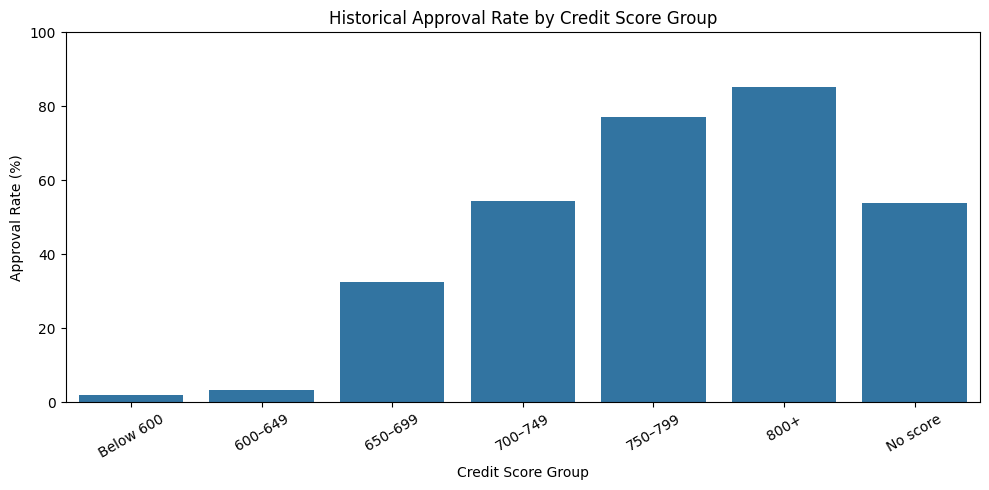

In [21]:
score_order = [
    "Below 600", "600–649", "650–699",
    "700–749", "750–799", "800+", "No score"
]

plot_data = credit_score_approval.reindex(score_order)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=plot_data.index,
    y=plot_data["Approval_Rate_Pct"]
)

plt.title("Historical Approval Rate by Credit Score Group")
plt.xlabel("Credit Score Group")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


### Analyzing Approval Rates by Employment Type

Employment type may be related to income stability and how the bank evaluates loan applications. We will calculate the number of applications and historical approval rate for each employment type.

This comparison will help us understand whether the bank's historical decisions differ between Salaried applicants, Self-Employed Professionals, Business Owners, and Gig / Contract workers. We will use the results to identify patterns, not to assume that employment type alone determines approval.


In [22]:
employment_approval = df_clean.groupby("employment_type")["decision"].agg(
    Total_Applications="count",
    Approved=lambda x: (x == "Approved").sum()
)

employment_approval["Approval_Rate_Pct"] = (
    employment_approval["Approved"]
    / employment_approval["Total_Applications"] * 100
).round(2)

employment_approval

,Total_Applications,Approved,Approval_Rate_Pct
employment_type,,,
Business Owner,1749,895,51.17
Gig / Contract,1766,617,34.94
Salaried,7057,4119,58.37
Self-Employed Professional,1428,722,50.56


Interpretation of the results
- Salaried: 58.37% approval rate — the highest.
- Business Owner: 51.17%.
- Self-Employed Professional: 50.56%.
- Gig / Contract: 34.94% — the lowest.
Business understanding: Salaried applicants have the highest historical approval rate, while Gig / Contract applicants have the lowest. This difference may reflect how the bank evaluates employment stability and other credit factors. We should investigate these patterns further rather than assume that employment type alone explains the decisions.


### Visualizing Approval Rates by Employment Type

We will use a bar chart to compare historical approval rates across the four employment types.

The chart will make it easier to identify differences between groups and communicate these findings to the lending team. These results describe past decisions and should not be treated as proof that employment type alone causes approval or rejection.


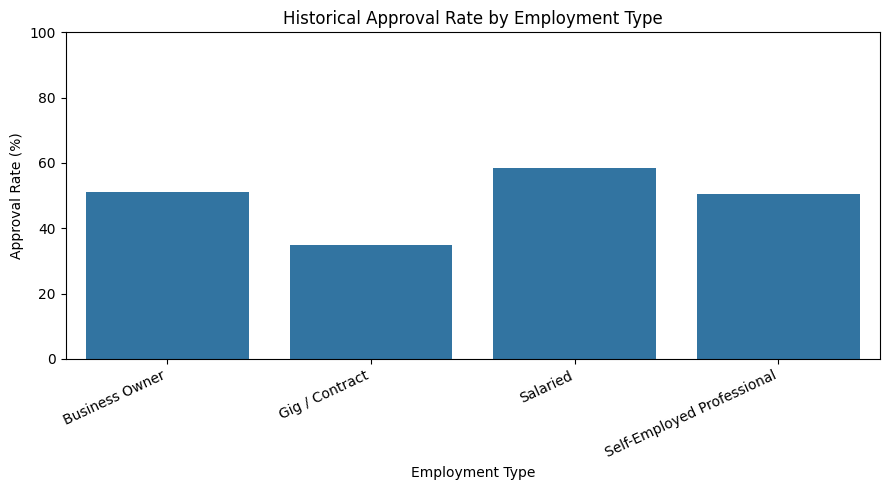

In [23]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=employment_approval.index,
    y=employment_approval["Approval_Rate_Pct"]
)

plt.title("Historical Approval Rate by Employment Type")
plt.xlabel("Employment Type")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


### Step 5.2 — Business Interpretation

**1. Credit Score Findings**
- Applicants with scores below 600 have only a 2.03% approval rate.
- Applicants with scores between 600 and 649 have a 3.22% approval rate.
- Applicants scoring 800 or above have the highest approval rate at 85.19%.
- Applicants with no credit score have a 53.90% approval rate, so they should be treated separately from low-score applicants.

**2. Employment Type Findings**
- Salaried applicants have the highest approval rate at 58.37%.
- Gig / Contract workers have the lowest approval rate at 34.94%.
- Business Owners have an approval rate of 51.17%.
- Self-Employed Professionals have an approval rate of 50.56%.

**3. Business Understanding**
- Historical approval rates generally increase as credit scores increase.
- The bank has historically approved very few applicants with scores below 650, but this does not prove an official bank policy.
- Employment type is also associated with different historical approval rates.
- Credit score and employment type should be considered alongside affordability and other credit factors when making lending decisions.



## Step 5.3 — Feature Engineering: FOIR and Loan-to-Income Ratio

Credit score is important, but the bank must also check whether an applicant can afford the proposed loan.

We will calculate two financial features using the cleaned dataset.

**1. FOIR (Fixed Obligation to Income Ratio)**

Formula: FOIR = (Existing EMI + Proposed EMI) / Monthly Income

FOIR shows how much of an applicant's monthly income is used for existing and proposed loan repayments. A higher FOIR means a greater repayment burden.

**2. Loan-to-Income Ratio**

Formula: Loan-to-Income Ratio = Loan Amount / (Monthly Income × 12)

This compares the requested loan amount with the applicant's annual income. A higher ratio means the requested loan is larger compared with annual income.

We have already created the `is_ntc` feature to identify applicants with no credit history. We will continue using it.

Next, we will analyze approval rates across different FOIR bands to understand how repayment burden relates to historical loan approval decisions.


### Calculate FOIR and Loan-to-Income Ratio

We will create the two required financial features using the cleaned dataset. FOIR measures the share of monthly income used for existing and proposed loan repayments. The loan-to-income ratio compares the requested loan amount with annual income. The `is_ntc` feature was created earlier.

In [25]:
# Calculate FOIR
df_clean["foir"] = (
    (df_clean["existing_emi"] + df_clean["proposed_emi"])
    / df_clean["monthly_income"]
)

# Calculate Loan-to-Income Ratio
df_clean["loan_to_income"] = (
    df_clean["loan_amount"]
    / (df_clean["monthly_income"] * 12)
)

# Display the newly created features
df_clean[[
    "monthly_income",
    "existing_emi",
    "proposed_emi",
    "foir",
    "loan_amount",
    "loan_to_income",
    "is_ntc"
]].head()

,monthly_income,existing_emi,proposed_emi,foir,loan_amount,loan_to_income,is_ntc
0,95000.0,23500.0,6600.0,0.316842,240000.0,0.210526,0
1,43000.0,8500.0,5000.0,0.313953,145000.0,0.281008,0
2,35000.0,3500.0,11800.0,0.437143,345000.0,0.821429,0
3,44500.0,0.0,4600.0,0.103371,135000.0,0.252809,1
4,83500.0,6000.0,33600.0,0.474251,700000.0,0.698603,0


In [26]:
# Create FOIR bands
df_clean["foir_band"] = np.select(
    [
        df_clean["foir"] < 0.30,
        (df_clean["foir"] >= 0.30) & (df_clean["foir"] < 0.40),
        (df_clean["foir"] >= 0.40) & (df_clean["foir"] < 0.50),
        (df_clean["foir"] >= 0.50) & (df_clean["foir"] <= 0.55),
        df_clean["foir"] > 0.55
    ],
    ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"],
    default="Unknown"
)

# Calculate approval rates
foir_approval = df_clean.groupby(
    "foir_band", observed=False
)["decision"].agg(
    Total_Applications="count",
    Approved=lambda x: (x == "Approved").sum()
)

foir_approval["Approval_Rate_Pct"] = (
    foir_approval["Approved"]
    / foir_approval["Total_Applications"] * 100
).round(2)

foir_approval

,Total_Applications,Approved,Approval_Rate_Pct
foir_band,,,
30–40%,2494,1471,58.98
40–50%,1764,845,47.90
50–55%,535,174,32.52
Above 55%,1711,266,15.55
Below 30%,5496,3597,65.45


### Step 5.3 — Business Interpretation

**1. FOIR Findings**
- Applicants with FOIR below 30% have the highest approval rate at 65.45%.
- Applicants with FOIR between 30% and 40% have an approval rate of 58.98%.
- The approval rate decreases to 47.90% for FOIR between 40% and 50%.
- For FOIR between 50% and 55%, the approval rate drops to 32.52%.
- Applicants with FOIR above 55% have the lowest approval rate at 15.55%.

**2. Business Understanding**
- Historical approval rates decrease as FOIR increases.
- The sharpest drop occurs when FOIR increases beyond 50%, especially above 55%.
- A FOIR limit of 50% could be considered for further evaluation because applicants above this level have substantially lower historical approval rates.
- This is a recommendation based on historical data, not proof of an official bank policy. FOIR should be considered along with credit score, income, and other risk factors.

### Visualize Approval Rates by FOIR Band

A bar chart will help us compare historical approval rates across the five FOIR bands. This makes it easier to see how approval rates change as applicants' repayment burden increases.

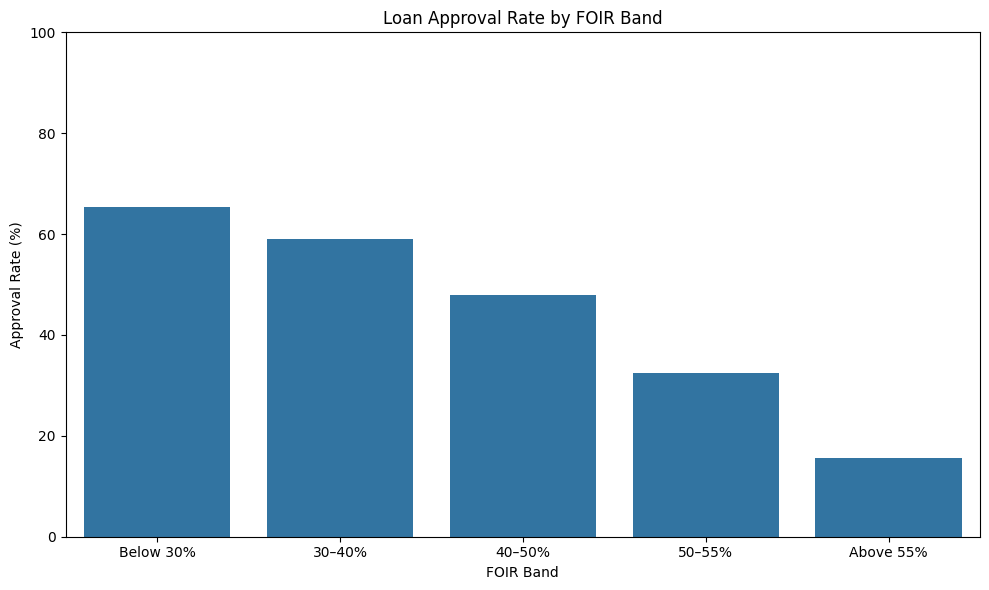

In [27]:
# Define the correct order of FOIR bands
foir_order = [
    "Below 30%",
    "30–40%",
    "40–50%",
    "50–55%",
    "Above 55%"
]

# Create the bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=foir_approval.reset_index(),
    x="foir_band",
    y="Approval_Rate_Pct",
    order=foir_order
)

plt.title("Loan Approval Rate by FOIR Band")
plt.xlabel("FOIR Band")
plt.ylabel("Approval Rate (%)")
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Step 5.4 — Baseline Logistic Regression Model

In this step, we will build a Logistic Regression model to predict whether a loan application is likely to be declined.

**Target variable**
- Declined = 1
- Approved = 0

**Features used by the model**
- Credit score
- New-to-credit indicator (`is_ntc`)
- FOIR
- Loan-to-income ratio
- Number of delinquencies in the last 24 months
- Number of active loans
- Years in the current job
- Age
- Loan tenure
- City tier
- Employment type
- Loan purpose

We will exclude application ID, application date, city, gender, and the decision column from the input features. These columns are excluded because they are identifiers, unnecessary for this baseline, or the target we want to predict.

We will handle missing credit scores using the median, encode categorical features, and scale numerical features. Then, we will split the data into 80% training data and 20% testing data, using stratification and `random_state=42`.

Finally, we will evaluate the model using accuracy, a confusion matrix, precision and recall for the Declined class, and the five largest model coefficients.


### Import Libraries for Logistic Regression

We will import the tools needed to prepare the data, split it into training and testing sets, build the Logistic Regression model, and evaluate its performance.

These tools help us train the model fairly and measure how well it identifies applications that were historically declined.

### Prepare the Target Variable and Input Features

The target variable is what we want the model to predict.

We will assign `1` to Declined applications and `0` to Approved applications. The model will learn patterns from the historical decisions.

We will select only the 12 features specified in the problem statement. We will exclude identifiers, application date, city, gender, and the original decision column from the inputs.

In [28]:
# Define the target variable
y = (df_clean["decision"] == "Declined").astype(int)

# Select the required input features
feature_columns = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier",
    "employment_type",
    "loan_purpose"
]

X = df_clean[feature_columns].copy()

# Display the target distribution and feature details
print("Target distribution (0 = Approved, 1 = Declined):")
print(y.value_counts().sort_index())

print("\nInput feature shape:", X.shape)
print("\nInput features:")
print(X.columns.tolist())

print("\nMissing values in selected features:")
print(X.isnull().sum())

Target distribution (0 = Approved, 1 = Declined):
decision
0    6353
1    5647
Name: count, dtype: int64

Input feature shape: (12000, 12)

Input features:
['credit_score', 'is_ntc', 'foir', 'loan_to_income', 'delinquencies_24m', 'num_active_loans', 'years_in_current_job', 'age', 'tenure_months', 'city_tier', 'employment_type', 'loan_purpose']

Missing values in selected features:
credit_score            1039
is_ntc                     0
foir                       0
loan_to_income             0
delinquencies_24m          0
num_active_loans           0
years_in_current_job       0
age                        0
tenure_months              0
city_tier                  0
employment_type            0
loan_purpose               0
dtype: int64


### Split the Data into Training and Testing Sets

We will divide the dataset into two parts:
- **80% training data:** Used to teach the model historical patterns.
- **20% testing data:** Used to evaluate how well the model predicts applications it has not seen during training.

We will use stratification to maintain a similar proportion of Approved and Declined applications in both sets. We will also use `random_state=42` to make the split reproducible.

### Import the Train-Test Split Function

We will import `train_test_split` from scikit-learn. This function divides the dataset into training and testing sets so we can train the model and evaluate its performance on unseen data.

In [30]:
# Split the data into training and testing sets
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

# Display the sizes of the datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

Training features: (9600, 12)
Testing features: (2400, 12)

Training target distribution:
decision
0    5082
1    4518
Name: count, dtype: int64

Testing target distribution:
decision
0    1271
1    1129
Name: count, dtype: int64


### Preprocess the Input Features

Numerical and categorical features need different preprocessing methods.

- **Numerical features:** Fill missing values using the median and scale the values so they are on comparable scales.
- **Categorical features:** Use one-hot encoding to convert employment type and loan purpose into numerical columns.

We will fit the preprocessing steps using only the training data and then apply the same transformations to the testing data. This prevents information from the test set from influencing preprocessing.

### Import Preprocessing Tools

We will import the tools required to handle missing values, scale numerical features, encode categorical features, and combine these operations into a preprocessing pipeline.

In [32]:
# Identify numerical and categorical features
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
numeric_features = [
    "credit_score",
    "is_ntc",
    "foir",
    "loan_to_income",
    "delinquencies_24m",
    "num_active_loans",
    "years_in_current_job",
    "age",
    "tenure_months",
    "city_tier"
]

categorical_features = [
    "employment_type",
    "loan_purpose"
]

# Preprocess numerical features
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocess categorical features
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine the preprocessing steps
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# Fit on training data and transform both datasets
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)
print("Missing values in original training credit scores:", X_train["credit_score"].isnull().sum())

Processed training data shape: (9600, 21)
Processed testing data shape: (2400, 21)
Missing values in original training credit scores: 836
